In [25]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_spec import *
import os
from tqdm import tqdm
import json
from datetime import date

In [95]:
# Get the current date
todays_date = date.today()
year = str(todays_date.year)
if todays_date.month < 10:
    month = '0'+str(todays_date.month)
else:
    month = str(todays_date.month)

if todays_date.day < 10:
    day = '0'+str(todays_date.day)
else:
    day = str(todays_date.day)

current_date = year+month+day
directory_name = 'results/'+current_date
if not os.path.isdir(directory_name):
    os.mkdir(directory_name)
    
directory_name

'results/20251023'

In [26]:
FINAL_PTIR_LikelyMPs = pd.read_excel('evaluation_data/FINAL_PTIR_LikelyMPs.xlsx', header=None).to_numpy().flatten()
FINAL_PTIR_Noise = pd.read_excel('evaluation_data/FINAL_PTIR_Noise.xlsx', header=None).to_numpy().flatten()
FINAL_PTIR_NonMPs = pd.read_excel('evaluation_data/FINAL_PTIR_NonMPs.xlsx', header=None).to_numpy().flatten()

In [27]:
df_background = pd.read_csv('329_MVCP_Sort_background.csv')
ids_background = np.array(df_background['ID'])

In [41]:
ids_background_2 = np.array(pd.read_excel('evaluation_data/MEC_05_004_PTIR_Noise.xlsx', header=None)).flatten()

In [107]:
ids_background_3 = pd.read_excel('evaluation_data/FINAL_PTIR_Noise (1).xlsx', header=None).to_numpy().flatten()

In [108]:
passive_data_ir = pd.read_csv('processed_data/passive_data_ir.csv')
del passive_data_ir['Unnamed: 0']
background_ids = np.array(passive_data_ir.query('background == "background"')['id'])
passive_data_ir.columns = list(np.float64(passive_data_ir.columns[:-4])) + list(passive_data_ir.columns[-4:])
passive_data_ir['polymer'] = ''
passive_data_ir['label'] = ''

passive_data_ir.iloc[:,:-6] = (passive_data_ir.iloc[:,:-6] - passive_data_ir.iloc[:,:-6].mean(1)[:,None]) / passive_data_ir.iloc[:,:-6].std(1)[:,None]

In [109]:
passive_data_background_mean = pd.read_csv('processed_data/passive_data_background_mean.csv')
del passive_data_background_mean['Unnamed: 0']

In [110]:
passive_data_background_mean.query('id in @ids_background_3').groupby('background').count()

,id
background,
background,104
no_background,101


In [112]:
XX = np.array(passive_data_ir.iloc[:,:-6].columns)
idx_bg = list(
    np.logical_or(np.logical_and(XX > 980, XX < 1170),
                       np.logical_or(np.logical_and(XX > 1290, XX < 1800),
                       np.logical_and(XX > 2720, XX < 2950))))

X = passive_data_ir.query('id in @ids_background_3').loc[:,idx_bg + [False]*6]
X_LMP = passive_data_ir.query('id in @FINAL_PTIR_LikelyMPs').loc[:,idx_bg + [False]*6]
X_NMP = passive_data_ir.query('id in @FINAL_PTIR_NonMPs').loc[:,idx_bg + [False]*6]
X2 = passive_data_ir.loc[:,idx_bg + [False]*6]

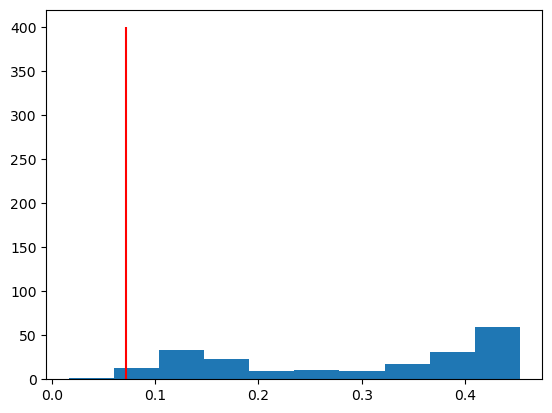

In [113]:
plt.hist(np.nanmean(np.abs(np.diff(X,1)), 1))
#plt.vlines(np.mean(np.nanmean(np.abs(np.diff(X,1)), 1)),0,400, color='red')

#plt.vlines(np.mean(np.nanmean(np.abs(np.diff(X,1)), 1))-3*np.std(np.nanmean(np.abs(np.diff(X,1)), 1)),
#           0,400, color='red')

plt.vlines(np.quantile(np.nanmean(np.abs(np.diff(X,1)), 1), .01), 0,400, color='red')

In [114]:
np.mean(np.nanmean(np.abs(np.diff(X,1)), 1))-3*np.std(np.nanmean(np.abs(np.diff(X,1)), 1))

-0.09478981900102995

In [115]:
np.quantile(np.nanmean(np.abs(np.diff(X,1)), 1), .01)

0.07162884001902903

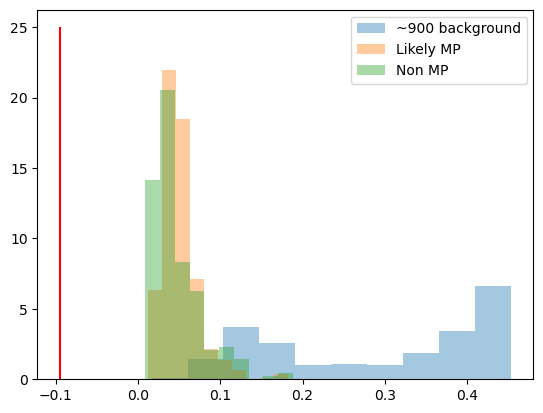

In [118]:
hist_background = plt.hist(np.nanmean(np.abs(np.diff(X,1)), 1), density=True, alpha=.4, label='~900 background')
plt.hist(np.nanmean(np.abs(np.diff(X_LMP,1)), 1), density=True, alpha=.4, label='Likely MP')
plt.hist(np.nanmean(np.abs(np.diff(X_NMP,1)), 1), density=True, alpha=.4, label='Non MP')
#plt.vlines(np.quantile(np.nanmean(np.abs(np.diff(X,1)), 1), .01), 0,25, color='red')
plt.vlines(np.mean(np.nanmean(np.abs(np.diff(X,1)), 1))-3*np.std(np.nanmean(np.abs(np.diff(X,1)), 1))
           , 0,25, color='red')
#plt.vlines(np.quantile(np.nanmean(np.abs(np.diff(X,1)), 1), .1), 0,25, color='green')
plt.legend()

In [100]:
passive_data_ir.query('id in @FINAL_PTIR_LikelyMPs').loc[np.nanmean(np.abs(np.diff(X_LMP,1)), 1) > 0.09353896086360994,'id'].reset_index(drop=True).reset_index()#.to_csv(directory_name+'/id_Likely_MP_removed_2sigma.csv')


,index,id
0,0,IAO_passive_August2024_K11_20240917_94
1,1,ICB_passive_November2024_C10_20241126_185
2,2,DC_passive_November2024_C5_20241113_18
3,3,DC_passive_November2024_C5_20241113_172
4,4,DC_passive_November2024_C5_20241113_175
5,5,FHS_passive_November2024_I5_20241119_47
6,6,FHS_passive_November2024_I5_20241119_74
7,7,FHS_passive_November2024_I5_20241119_170
8,8,IAO_passive_November2024_J4_20241120_162
9,9,FHS_passive_AprMay2024_B8_20240604_18


In [82]:
(
np.mean(np.nanmean(np.abs(np.diff(X_LMP,1)), 1) > 0.0761683674474753),
np.mean(np.nanmean(np.abs(np.diff(X_NMP,1)), 1) > 0.09353896086360)
)

(0.1023454157782516, 0.08208955223880597)

In [69]:
(
np.mean(np.nanmean(np.abs(np.diff(X_LMP,1)), 1) > 0.0935),
np.mean(np.nanmean(np.abs(np.diff(X_NMP,1)), 1) > 0.0935)
)

(0.046908315565031986, 0.08208955223880597)

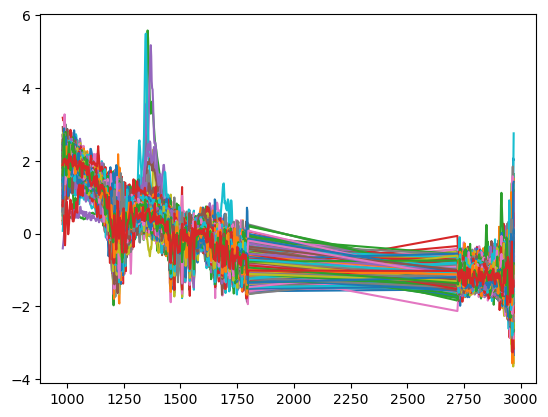

In [37]:
_ = plt.plot(X.T)#, color='blue', alpha=.1)

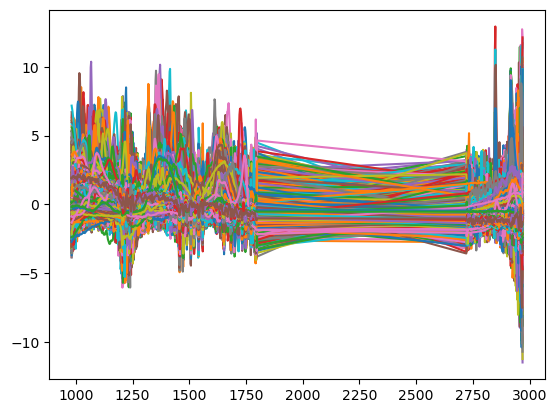

In [38]:
_ = plt.plot(X2.T)